# 4. Benchmark and replay

Two ways to test a sampler without spending a single real model:

1. **A synthetic benchmark** whose answer is known: the two-basin objective of the paper (Appendix B), a broad
   shallow basin next to a narrow, tilted, deeper one, with χ² scatter of 47 and, optionally, a region where models
   fail. We compare the full method with the same search stripped of its scatter-robust components and with Sobol
   sampling alone.
2. **A replay on an archive**: an existing set of evaluated models (here a synthetic dense grid) answers every
   proposal with its nearest archived model, so the campaign can be compared with the archive's own grid on equal
   terms.

In [1]:
import os
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(v, "1")      # exact reproducibility needs a fixed number of linear-algebra threads
import numpy as np
import pandas as pd
import sagari as sg
from sagari.benchmark import TwoBasin, PILOT_SPACE, NOISE
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False})
INK, BLUE, ORANGE, GRAY = "#222222", "#2a78d6", "#eb6834", "#9a9a9a"
UPS, MBH = r"$\Upsilon$", r"$M_\bullet$"

## The two-basin benchmark

A trial: 256 Sobol points and five rounds of 128. After each round we ask whether the smoothed estimate's best
point lies in the deeper basin. The paper ran 100 trials per sampler (`benchmarks/two_basin.py`); a few are enough
to see the difference.

In [2]:
VARIANTS = {
    "full":    dict(kernel="matern52", train_window=30.0, global_fraction=0.35),
    "ablated": dict(kernel="rbf", train_window=None, global_fraction=0.15, incumbent="raw", n_local_candidates=0,
                    min_separation=0.0, verify=False, redraw_candidates=False),
    "sobol":   None,
}

def trial(variant, seed, hopeless=True, n0=256, nr=128, rounds=5):
    obj, space = TwoBasin(hopeless=hopeless), PILOT_SPACE
    rng = np.random.default_rng(seed)
    sob = sg.SobolGlobalDesign(space.dim, seed)
    d = sg.initial_design(space, n0, sob)
    table = d[space.free_params].copy(); table["chi2"] = obj(d, rng)
    out = []
    for r in range(rounds + 1):
        if r:
            d = (sg.initial_design(space, nr, sob) if VARIANTS[variant] is None else
                 sg.propose_round(table, space, nr, sob, seed=seed, noise_diagnostic=False, **VARIANTS[variant]))
            new = d[space.free_params].copy(); new["chi2"] = obj(d, rng)
            table = pd.concat([table, new], ignore_index=True)
        est = sg.smoothed_estimate(table, space, seed=seed)
        f, in_n = obj.true(space.to_unit(table))
        out.append(dict(variant=variant, seed=seed, n=len(table), found=obj.found(est), mbh_err=obj.mbh_error(est),
                        near_deep=int((((f - 1000) < 2 * NOISE) & in_n).sum())))
    return out, table

N_TRIALS = 4          # the paper: 100
rows, tables = [], {}
for v in VARIANTS:
    for s in range(N_TRIALS):
        r, t = trial(v, 1000 + s)
        rows += r; tables[v, 1000 + s] = t
bench = pd.DataFrame(rows)
bench[bench["n"] == bench["n"].max()].groupby("variant")[["found", "mbh_err", "near_deep"]].agg(
    found=("found", "mean"), median_mbh_err_dex=("mbh_err", "median"), median_models_near_deep_min=("near_deep", "median"))

,found,median_mbh_err_dex,median_models_near_deep_min
variant,,,
ablated,0.50,0.386509,21.5
full,0.75,0.148285,260.5
sobol,0.00,0.704428,4.5


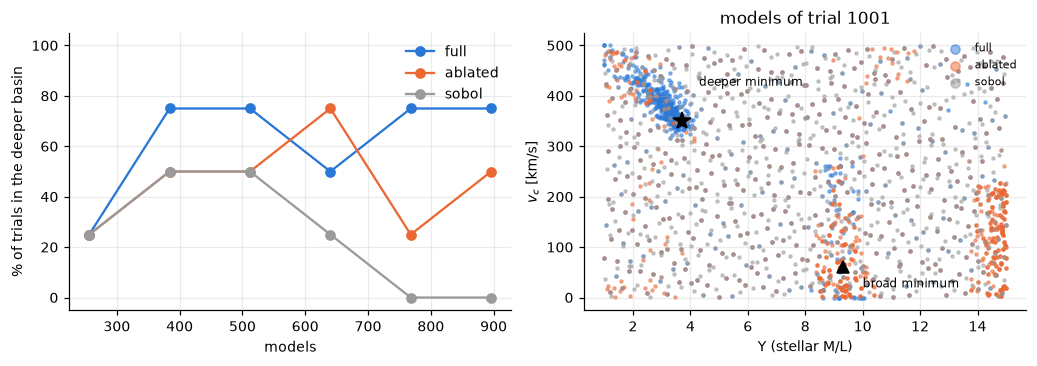

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
for v, col in zip(VARIANTS, (BLUE, ORANGE, GRAY)):
    g = bench[bench.variant == v].groupby("n")["found"].mean()
    ax[0].plot(g.index, 100 * g.values, "o-", color=col, label=v)
ax[0].set(xlabel="models", ylabel="% of trials in the deeper basin", ylim=(-5, 105)); ax[0].legend()
fin = bench[bench["n"] == bench["n"].max()]
shown = int(fin[(fin.variant == "full") & fin.found]["seed"].min())       # a trial in which the full method succeeded
for v, col in zip(VARIANTS, (BLUE, ORANGE, GRAY)):
    t = tables[v, shown]; ok = t["chi2"].notna()
    ax[1].scatter(t.loc[ok, "upsilon"], t.loc[ok, "v_c"], s=4, alpha=0.5, color=col, label=v)
ax[1].plot(3.7, 350, "k*", ms=12); ax[1].annotate("deeper minimum", (3.7, 350), (4.3, 420), fontsize=8)
ax[1].plot(9.3, 60, "k^", ms=8); ax[1].annotate("broad minimum", (9.3, 60), (10.0, 20), fontsize=8)
ax[1].set(xlabel=UPS + " (stellar M/L)", ylabel=r"$v_c$ [km/s]", title=f"models of trial {shown}")
ax[1].legend(fontsize=7, markerscale=3, loc="upper right")
plt.tight_layout()

In the trial shown, the full method concentrates its models in the narrow deeper basin. The ablated search,
which trusts its single lowest model and lacks the small-scale candidates, mostly refines the broad basin it
found first, and Sobol sampling alone covers the box evenly and never lands enough models in the narrow basin.
When the full method fails (here in one of four trials; in the paper, in 9 of 100), it behaves like the
ablated search and refines the broad basin.

## Replaying a campaign on an archive

To compare with a grid on the same footing, give the campaign an archive of already-evaluated models.
`replay.archive_evaluator` answers each proposal with the nearest archived model (and its real χ², or its failure),
so no interpolated value ever enters the loop. Here the archive is a dense 4-D grid on the two-basin surface.

In [4]:
from sagari.replay import archive_evaluator
obj = TwoBasin(hopeless=False)
g = np.meshgrid(*[np.linspace(0, 1, 14)] * 4, indexing="ij")
grid = PILOT_SPACE.from_unit(np.column_stack([x.ravel() for x in g]))
grid["chi2"] = obj(grid, np.random.default_rng(0))
print(f"archive: a {len(grid)}-model grid")

c = sg.Campaign.create("replay_campaign", PILOT_SPACE, overwrite=True, seed=7, converge_on=["mbh", "upsilon"])
res = c.run(archive_evaluator(grid, PILOT_SPACE.free_params), verbose=False)
st = c.status(res, verbose=False)
e = st["history"][-1]["estimate"]
print(f"replay used {len(res)} models ({len(res.drop_duplicates(PILOT_SPACE.free_params))} distinct archived ones), "
      f"{len(grid)/len(res):.0f} times fewer than the grid; search stopped at round {st['converged_at_round']}")
print(f"best point in the deeper basin: {obj.found(e)}  (M_BH {e['mbh'][0]:.3g}, Upsilon {e['upsilon'][0]:.2f}, v_c {e['v_c'][0]:.0f})")
gp, _, _ = c.surrogate(res)
prof = sg.posterior.profiles(gp, PILOT_SPACE, c.seed, params=["mbh"])
(lo, hi), = sg.posterior.profile_intervals(prof, PILOT_SPACE, levels=(4.0,))["mbh"][4.0]
print(f"M_BH within Delta chi2 = 4: {lo:.3g} - {hi:.3g}  (true deeper minimum 8e8)")

archive: a 38416-model grid


replay used 896 models (732 distinct archived ones), 43 times fewer than the grid; search stopped at round 2
best point in the deeper basin: True  (M_BH 1.43e+09, Upsilon 3.57, v_c 341)


M_BH within Delta chi2 = 4: 7.4e+08 - 1.23e+09  (true deeper minimum 8e8)


Replays like this one, on the archived models of two published black hole campaigns, are how the paper
measured the factor of 9–30 in cost. For your own archive, load it as a table with the free-parameter columns and
`chi2` (NaN for failed models) and pass it to `archive_evaluator`.

To reproduce the paper's benchmark exactly, run `python benchmarks/two_basin.py 100` and
`python benchmarks/two_basin.py 100 --hopeless`.